# DSC212 Graph Theory — Research Assignment
# Name : JYOTHIKA MATTUMMAL
# Roll No. : IMS25102
## Modularity on the Karate Club Graph: Recursive Spectral Modularity Partitioning

**Course:** DSC212 Graph Theory Module  
**Method:** Spectral modularity maximisation with recursive bisection (Newman, 2006)  
**Tools:** Python, NumPy, NetworkX, Matplotlib, Pandas

---
### How to read this notebook
Every section has the same pattern: **(1) concept → (2) formula → (3) code → (4) output → (5) explanation of the output.**
All numbers and plots below are produced by the code in this notebook; nothing is typed in by hand.

### Contents
1. Introduction  
2. Importing libraries and loading the dataset  
3. Adjacency matrix and degree vector  
4. The modularity matrix  
5. The modularity score  
6. Spectral bipartitioning  
7. Recursive spectral partitioning  
8. Visualising every split  
9. Network metrics  
10. Storing the metric values  
11. Plotting metric evolution  
12. Comparison with the historical factions  
13. Results and discussion  
14. Conclusion  
15. References

# Section 1: Introduction

**Graph.** A graph $G=(V,E)$ is a set of **nodes** (vertices) $V$ together with a set of **edges** $E$, where each edge joins two nodes. Here $n=|V|$ is the number of nodes and $m=|E|$ is the number of edges. In this project the graph is *undirected* (an edge has no direction) and *unweighted* (all edges count equally).

**What nodes and edges mean here.** In a social network, a node is a person and an edge says "these two people interact".

**The Zachary Karate Club.** In the early 1970s the anthropologist Wayne Zachary spent two years observing 34 members of a university karate club. He drew an edge between two members if they interacted regularly outside classes (78 edges in total). During his study the instructor ("Mr. Hi") and the club administrator (the "Officer"/president) quarrelled about money, and the club split into two factions. Zachary's friendship network, recorded *before* the split, turned out to predict who followed whom. That is why the graph is the "hello world" of community detection.

**Community detection.** A *community* is a group of nodes with many edges *inside* the group and relatively few edges to the outside. Community detection means finding such groups from the graph structure alone.

**Modularity.** Counting how many edges lie inside groups is not enough, because a big group naturally contains many edges by chance. Modularity measures *how many more* edges lie inside the groups than we would expect in a random graph in which every node keeps its degree (the **null model**).

**Spectral partitioning.** Finding the best split directly means checking $2^n$ labellings, which is impossible. Spectral partitioning *relaxes* the problem so that it is solved exactly by the **leading eigenvector** of the **modularity matrix** $B$. The signs of that eigenvector give the split.

**Recursive bisection.** One split gives only two groups. We apply the same test again inside each group (using the restricted matrix $B^{(C)}$) until no group can be split any more. This gives many communities.

### Objectives
1. Implement recursive spectral modularity partitioning from scratch.
2. Visualise the graph after every accepted split.
3. After every split compute degree, betweenness, closeness centrality and clustering coefficient for every node, and store them.
4. Plot how each metric evolves per node.
5. Discuss which nodes stay central and how community structure affects the metrics.
6. Compare the result (afterwards only) with the historical split.

The method follows the assignment handout, which is based on Newman (2006) [1].

# Section 2: Importing libraries and loading the dataset

| Library | Used for |
|---|---|
| `numpy` (`np`) | matrices, vectors, eigenvalues, eigenvectors |
| `networkx` (`nx`) | building the graph, centrality measures, drawing |
| `matplotlib.pyplot` (`plt`) | figures and plots |
| `pandas` (`pd`) | tables (DataFrames) |

**`nx.karate_club_graph()`** takes no arguments and returns a NetworkX `Graph` object containing Zachary's network. The data is built into NetworkX, so no download is needed. Each node also stores an attribute `'club'` (`'Mr. Hi'` or `'Officer'`) with the historical faction. **We will not look at this attribute until Section 12**, so it cannot influence the algorithm.

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Make tables a little easier to read
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 150)

# Load Zachary's Karate Club graph (34 nodes, 78 edges, node IDs 0..33)
G = nx.karate_club_graph()

nodes = list(G.nodes())          # list of node IDs, we keep the ORIGINAL IDs
n = G.number_of_nodes()          # number of nodes
m = G.number_of_edges()          # number of edges

print("Number of nodes n =", n)
print("Number of edges m =", m)
print("Node IDs          =", nodes)
print("Is graph connected?", nx.is_connected(G))

Number of nodes n = 34
Number of edges m = 78
Node IDs          = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Is graph connected? True


**Reading the output.** The graph has 34 nodes and 78 edges, the node IDs are $0,1,\dots,33$, and the graph is connected (there is a path between every pair of nodes). These match the assignment.

Because the IDs are exactly $0,\dots,33$, node ID $i$ also equals row/column $i$ of every matrix we build. We check this explicitly, because later we use node IDs as matrix indices.

### The fixed layout
**`nx.spring_layout(G, seed=42)`** computes 2-D coordinates for every node. It imitates physics: edges act like springs pulling connected nodes together, while all nodes repel each other. It returns a dictionary `{node: (x, y)}`. The layout starts from random positions, so `seed=42` makes the result reproducible. **We compute it once and reuse it in every figure**, so a node never moves between pictures.

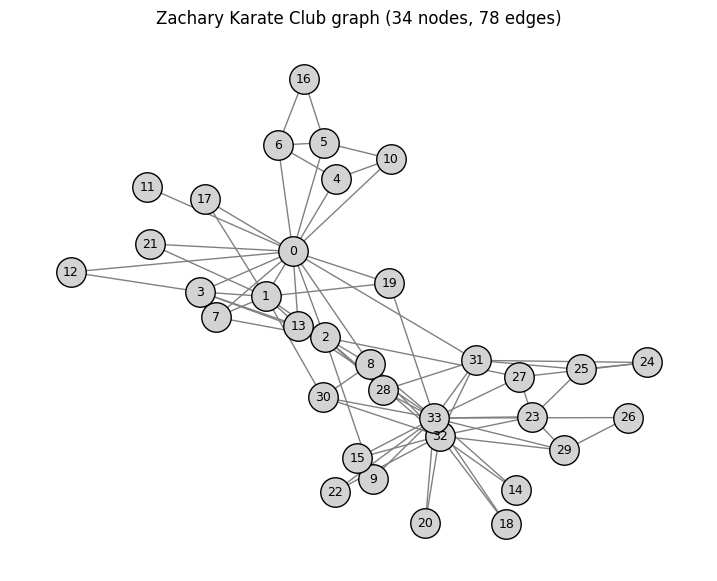

In [ ]:
# Safety check: node IDs must equal 0,1,...,n-1 so that "node i" = "row i" of the matrices
assert nodes == list(range(n)), "Node IDs are not 0..n-1"

# Fixed layout, calculated ONCE and reused everywhere
pos = nx.spring_layout(G, seed=42)

# A palette of colours for communities (index 0 = first community, ...)
COLORS = ["#6baed6", "#fd8d3c", "#74c476", "#fb6a4a",
          "#9e9ac8", "#d9b38c", "#f2a6d0", "#7fd6d6"]

plt.figure(figsize=(9, 7))
nx.draw_networkx(G, pos,
                 node_color="lightgray",   # colour of the node circles
                 edgecolors="black",       # outline colour of the circles
                 node_size=450,            # size of each circle
                 font_size=9,              # size of the node-ID labels
                 edge_color="gray")        # colour of the edges
plt.title("Zachary Karate Club graph (34 nodes, 78 edges)")
plt.axis("off")
plt.show()

**Explanation of the drawing function.** `nx.draw_networkx(G, pos, ...)` draws nodes, edges and labels in one call. `pos` tells it where each node goes; `node_color`, `node_size`, `edge_color`, `font_size` control the appearance. Nodes 0 and 33 (the instructor and the administrator) are drawn in the middle of two dense regions; most other nodes are attached to one of them.

**Why this dataset is popular.** It is small enough to understand completely, real (not synthetic), and we know a historical "ground truth" split, so we can judge whether an algorithm finds something meaningful.

# Section 3: Constructing the adjacency matrix

For an undirected graph with $n$ nodes the **adjacency matrix** $A$ is an $n\times n$ table:

$$
A_{ij} =
\begin{cases}
1 & \text{if nodes } i \text{ and } j \text{ are connected}\\
0 & \text{otherwise}
\end{cases}
$$

* **Rows and columns:** row $i$ and column $i$ both belong to node $i$. Entry $A_{ij}$ answers "is there an edge between $i$ and $j$?".
* **Symmetric:** an undirected edge $i-j$ is also $j-i$, so $A_{ij}=A_{ji}$, i.e. $A^T=A$.
* **Diagonal:** $A_{ii}$ would be a self-loop (a node linked to itself). The Karate graph has none, so the diagonal is all zeros.
* **Degree:** the degree $k_i$ of node $i$ is the number of its neighbours, which is the number of 1's in row $i$:
$$k_i=\sum_j A_{ij}$$
* **Handshake relation:** every edge has two ends, so adding all degrees counts each edge twice:
$$\sum_i k_i = 2m$$

**Functions used**

* `nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)` — *takes* a graph, the node order (`nodelist`), the data type, and `weight=None` ("ignore edge weights, put 1 for every edge"). This last argument matters: newer NetworkX versions store a `weight` attribute on the Karate Club edges, and by default `to_numpy_array` would then put those weights in the matrix instead of 0/1, which would break $\\sum_i k_i=2m$. It *returns* the adjacency matrix as an $n\times n$ NumPy array. Passing `nodelist=nodes` guarantees row $i$ is node `nodes[i]`.
* `A.sum(axis=1)` — adds the numbers **along each row** (`axis=1` means "collapse the columns"). Result: a vector of length $n$ with one row-sum per node, i.e. the degree vector $k$.

In [ ]:
# Adjacency matrix
# NOTE: weight=None means "ignore any edge-weight attribute and use 0/1 entries".
# (Recent NetworkX versions attach a 'weight' attribute to the Karate Club edges;
#  the assignment uses the plain unweighted graph, so we must switch the weights off.)
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)

# Degree vector: row sums of A
degrees = A.sum(axis=1)

print("Shape of A       :", A.shape)
print("Shape of degrees :", degrees.shape)
print("Number of edges m:", m)
print("Sum of degrees   :", degrees.sum(), " and 2m =", 2 * m)

print("\nIs A symmetric?          ", np.allclose(A, A.T))
print("Is the diagonal all zero?", np.all(np.diag(A) == 0))

# Compare with NetworkX's own degree values
nx_degrees = np.array([G.degree(node) for node in nodes])
print("Degrees agree with NetworkX?", np.allclose(degrees, nx_degrees))
print("Entries of A are only 0 or 1?", set(np.unique(A)) == {0.0, 1.0})

print("\nDegrees of the first 10 nodes:", degrees[:10])
print("Top-left 6x6 corner of A:")
print(A[:6, :6])

Shape of A       : (34, 34)
Shape of degrees : (34,)
Number of edges m: 78
Sum of degrees   : 156.0  and 2m = 156

Is A symmetric?           True
Is the diagonal all zero? True
Degrees agree with NetworkX? True
Entries of A are only 0 or 1? True

Degrees of the first 10 nodes: [16.  9. 10.  6.  3.  4.  4.  4.  5.  2.]
Top-left 6x6 corner of A:
[[0. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 0. 0.]
 [1. 1. 0. 1. 0. 0.]
 [1. 1. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]


**Reading the output.** $A$ is $34\times34$, the degree vector has 34 entries, and $\sum_i k_i = 156 = 2\times78$, confirming the handshake relation. $A$ is symmetric with a zero diagonal, and our degrees agree with NetworkX. `np.allclose(x, y)` tests whether two arrays are equal up to tiny floating-point errors; we use it instead of `==` for decimal numbers.

# Section 4: Constructing the modularity matrix

The assignment defines the **modularity matrix**

$$
B = A - \frac{k\,k^{T}}{2m}, \qquad B_{ij}=A_{ij}-\frac{k_i k_j}{2m}.
$$

### Meaning of each term
* $A$ — **actual** connectivity: $A_{ij}=1$ if the edge really exists.
* $k$ — the degree vector, a column of $n$ numbers ($n\times1$). $k^T$ is the same list as a row ($1\times n$).
* $k\,k^T$ — the **outer product**. Multiplying an $n\times1$ column by a $1\times n$ row gives an $n\times n$ matrix whose $(i,j)$ entry is $k_i k_j$. In NumPy: `np.outer(degrees, degrees)`. It makes *every* pair $(i,j)$ in one step instead of a double loop. Example: for $k=(1,2,3)$ the outer product is the $3\times3$ table of all products $1,2,3;\ 2,4,6;\ 3,6,9$.
* $2m$ — total number of "stubs" (half-edges). Each of the $m$ edges has two ends.

### The null model
Imagine removing all edges but keeping every node's stubs: node $i$ has $k_i$ stubs. Now join the $2m$ stubs randomly in pairs. One particular stub of $i$ is matched with a stub of $j$ with probability about $k_j/2m$ (a fraction $k_j/2m$ of all stubs belongs to $j$). Node $i$ has $k_i$ stubs, so the **expected number of edges** between $i$ and $j$ is
$$\frac{k_i k_j}{2m}.$$
So the matrix $\dfrac{kk^T}{2m}$ contains the expected edge counts under this random model, in which high-degree nodes are still more likely to connect.

### Why subtract?
$B_{ij}=$ (actual edge) $-$ (expected edge).
* $B_{ij}>0$: $i$ and $j$ are **more** connected than chance (e.g. a real edge between two low-degree nodes). Putting them together is "surprisingly good".
* $B_{ij}<0$: less connected than chance (e.g. no edge between two big hubs). Putting them together is not supported by the data.

### Properties we verify
1. $B$ is $n\times n$.
2. $B$ is symmetric ($B^T=B$), because $A^T=A$ and $(kk^T)^T=kk^T$ (Proposition 1). Symmetric real matrices have real eigenvalues and orthonormal eigenvectors (Theorem 1), which is exactly what the eigen-decomposition later needs.
3. Every **row sum is 0**, i.e. $B\mathbf 1=0$ (Proposition 2): $B\mathbf 1 = A\mathbf 1-\frac{k(k^T\mathbf 1)}{2m}=k-\frac{k\cdot 2m}{2m}=0$. Meaning: for each node, total actual degree equals total expected degree.

In [ ]:
# Outer product of the degree vector with itself: an n x n matrix of all products k_i * k_j
degree_outer = np.outer(degrees, degrees)

# Expected number of edges between every pair (i, j) under the null model
expected_edges = degree_outer / (2 * m)

# Modularity matrix  B = A - k k^T / (2m)
B = A - np.outer(degrees, degrees) / (2 * m)

print("Shape of A              :", A.shape)
print("Shape of degrees (k)    :", degrees.shape)
print("Shape of np.outer(k, k) :", degree_outer.shape)
print("Shape of B              :", B.shape)

print("\nIs B symmetric?               ", np.allclose(B, B.T))
row_sums = B.sum(axis=1)
print("Largest |row sum| of B        :", np.abs(row_sums).max())
print("Are all row sums approx. zero? ", np.allclose(row_sums, 0))

# A concrete example: nodes 0 and 33 (two hubs) and nodes 0 and 1
print("\nExample, nodes 0 and 33:  A =", A[0, 33],
      " expected =", round(expected_edges[0, 33], 3), " B =", round(B[0, 33], 3))
print("Example, nodes 0 and 1 :  A =", A[0, 1],
      " expected =", round(expected_edges[0, 1], 3), " B =", round(B[0, 1], 3))

Shape of A              : (34, 34)
Shape of degrees (k)    : (34,)
Shape of np.outer(k, k) : (34, 34)
Shape of B              : (34, 34)

Is B symmetric?                True
Largest |row sum| of B        : 8.881784197001252e-16
Are all row sums approx. zero?  True

Example, nodes 0 and 33:  A = 0.0  expected = 1.744  B = -1.744
Example, nodes 0 and 1 :  A = 1.0  expected = 0.923  B = 0.077


**Reading the output.** All shapes are as expected ($34\times34$ for the matrices, 34 for the vector). $B$ is symmetric and every row sum is zero up to floating-point error (a number like $10^{-15}$ is "zero" for a computer; that is why we say *approximately* zero).

The two examples show the idea: nodes 0 and 33 are both hubs and are **not** connected, so $A=0$ but chance expects a sizeable value, giving a negative $B_{ij}$ ("they would be expected to be linked, but are not"). Nodes 0 and 1 are linked, and the expected value is smaller than 1, so $B_{ij}>0$.

Because the row sums are zero, $B\mathbf 1=0$, so the **all-ones vector is an eigenvector of $B$ with eigenvalue 0**. The "trivial partition" (everybody in one group) therefore has modularity exactly 0 (Corollary 1). We will use this in Section 6.

# Section 5: Understanding the modularity score

### Encoding a two-community split
A split of the nodes into two groups is stored in a **label vector** $s\in\{-1,+1\}^n$:

$$
s_i=\begin{cases}+1 & \text{if node } i \text{ is in community 1}\\ -1 & \text{if node } i \text{ is in community 2}\end{cases}
$$

**Why $\pm1$?** The product $s_is_j$ is $+1$ if $i,j$ are in the *same* group and $-1$ if they are in *different* groups. So $s_is_j$ automatically "switches on" the pairs that share a community.

### The modularity score
$$
Q=\frac{1}{4m}\,s^{T}Bs=\frac{1}{4m}\sum_{i=1}^{n}\sum_{j=1}^{n}B_{ij}\,s_is_j .
$$

* $s^T$ is $1\times n$, $B$ is $n\times n$, $s$ is $n\times1$. So $s^TBs$ is $(1\times n)(n\times n)(n\times1)=1\times1$: a **single number (scalar)**. Expressions of the form $x^TBx$ are called **quadratic forms**.
* Pairs in the same group contribute $+B_{ij}$ and pairs in different groups contribute $-B_{ij}$. Good splits put pairs with large positive $B_{ij}$ together.
* **$Q>0$** means there are more edges inside the groups than the null model predicts: a meaningful community structure. $Q\approx0$ means "no better than random".
* **Maximising $Q$** gives the split that deviates most from randomness, and avoids the useless "cut off one node" solution that a plain minimum-cut would choose.
* The factor $\frac1{4m}$ is a normalisation so that $Q$ is at most 1.

### Small numerical example
Two triangles $\{0,1,2\}$ and $\{3,4,5\}$ joined by one edge $2-3$ ($m=7$). We build $A,k,B$ with the same steps as above and compute $Q$ for three label vectors.

In [ ]:
# ---- Tiny example graph: two triangles joined by one edge ----
toy = nx.Graph()
toy.add_edges_from([(0, 1), (0, 2), (1, 2),      # triangle 1
                    (3, 4), (3, 5), (4, 5),      # triangle 2
                    (2, 3)])                     # the bridge edge
toy_nodes = list(toy.nodes())
A_toy = nx.to_numpy_array(toy, nodelist=toy_nodes, dtype=float)
k_toy = A_toy.sum(axis=1)
m_toy = toy.number_of_edges()
B_toy = A_toy - np.outer(k_toy, k_toy) / (2 * m_toy)

def modularity_from_labels(B_matrix, s_vector, edges):
    # Q = (1 / 4m) * s^T B s     (np.dot multiplies; @ is the same thing)
    quadratic_form = s_vector @ B_matrix @ s_vector
    return quadratic_form / (4 * edges)

s_good  = np.array([+1, +1, +1, -1, -1, -1])   # triangle vs triangle
s_bad   = np.array([+1, -1, +1, -1, +1, -1])   # mixed up
s_trivial = np.ones(6)                         # everyone together

print("Q for the 'two triangles' split :", round(modularity_from_labels(B_toy, s_good, m_toy), 4))
print("Q for a mixed-up split          :", round(modularity_from_labels(B_toy, s_bad, m_toy), 4))
print("Q for the trivial split (s = 1) :", round(modularity_from_labels(B_toy, s_trivial, m_toy), 4))

# Cross-check with NetworkX's built-in modularity (used ONLY as a check)
nx_Q = nx.community.modularity(toy, [{0, 1, 2}, {3, 4, 5}])
print("NetworkX modularity of the triangle split:", round(nx_Q, 4))

Q for the 'two triangles' split : 0.3571
Q for a mixed-up split          : -0.2143
Q for the trivial split (s = 1) : -0.0
NetworkX modularity of the triangle split: 0.3571


**Reading the output.** The natural split into the two triangles gets a clearly positive $Q$ (and it matches NetworkX's own modularity function, which we use *only as a check*). The mixed-up split is negative, and the trivial split gives exactly 0, as predicted by Corollary 1. So $Q$ rewards the split that a human would pick.

`s @ B @ s` is NumPy's matrix product: first $Bs$ (a vector), then $s^T(Bs)$ (a single number).

# Section 6: Spectral bipartitioning

### Why not just try all splits?
Each of the $n$ nodes has two possible labels, so there are $2^n$ vectors $s$. For $n=34$ that is $2^{34}\approx1.7\times10^{10}$; for a 1000-node network the number is astronomically large. We need a shortcut.

### Relaxation
We **relax** the problem: instead of forcing $s_i=\pm1$, allow *any real numbers* but keep the length fixed, $\|s\|_2=\sqrt{\sum_i s_i^2}=1$:

$$\max_{\|s\|_2=1}\; s^{T}Bs .$$

(A $\pm1$ vector has length $\sqrt n$, not 1, but rescaling by $1/\sqrt n$ does not change which vector is best, only the size of $s^TBs$.)

### Eigenvalues and eigenvectors
For a square matrix $B$, a non-zero vector $u$ and a number $\lambda$ with
$$Bu=\lambda u$$
are an **eigenvector** and **eigenvalue**: multiplying by $B$ only *stretches* $u$ by $\lambda$ without changing its direction. For a real symmetric $B$ all eigenvalues are real and the eigenvectors can be chosen orthonormal (Theorem 1).

### Rayleigh–Ritz theorem (Theorem 2)
Order the eigenvalues $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_n$ with orthonormal eigenvectors $u_1,\dots,u_n$. Write any unit vector as $s=\sum_i\alpha_iu_i$ with $\sum\alpha_i^2=1$. Then
$$s^TBs=\sum_i\alpha_i^2\lambda_i\le\lambda_1\sum_i\alpha_i^2=\lambda_1,$$
with equality for $s=u_1$. So **the maximum is the largest eigenvalue $\lambda_1$ and it is attained by the leading eigenvector $u_1$.**

### Interpreting $u_1$
$u_1$ is a "soft" label vector: a large positive entry means the node strongly belongs with the "+" side, a large negative entry with the "−" side, an entry near 0 means no strong preference. To get a hard split we use the signs:
$$
s_i=\begin{cases}+1 & u_i>0\\-1 & \text{otherwise.}\end{cases}
$$

> **Important:** this is a *spectral approximation*. The relaxed problem is solved exactly, but rounding to signs can lose something, so we do **not** claim the result is the globally optimal discrete split.

### Functions used
* **`np.linalg.eigh(B)`** — "eigen-decomposition for a **h**ermitian (real symmetric) matrix". *Takes* a symmetric matrix. *Returns two things:* `eigenvalues` (a 1-D array of length $n$, sorted from **smallest to largest**) and `eigenvectors` (an $n\times n$ array whose **column** `eigenvectors[:, i]` is the unit-length eigenvector for `eigenvalues[i]`). It is the right tool for symmetric matrices because it is faster and more accurate than the general `np.linalg.eig`, and it guarantees real eigenvalues and orthonormal eigenvectors.
* **`np.argmax(x)`** — returns the *position* (index) of the largest number in `x`. We use it instead of assuming "last = largest", so the code stays correct.
* **`np.where(condition, a, b)`** — builds an array that has `a` where the condition is true and `b` elsewhere. We use it to turn $u_1$ into $\pm1$ labels.

In [ ]:
# Eigen-decomposition of the symmetric matrix B
eigenvalues, eigenvectors = np.linalg.eigh(B)

print("Shape of eigenvalues :", eigenvalues.shape)
print("Shape of eigenvectors:", eigenvectors.shape)

# Position of the largest eigenvalue, then pick it and its eigenvector (a COLUMN)
index_largest = np.argmax(eigenvalues)
largest_eigenvalue = eigenvalues[index_largest]
leading_eigenvector = eigenvectors[:, index_largest]

print("\nLargest eigenvalue lambda_1 =", round(largest_eigenvalue, 5))
print("Five largest eigenvalues     =", np.round(np.sort(eigenvalues)[::-1][:5], 4))
print("Length (norm) of leading eigenvector =", round(np.linalg.norm(leading_eigenvector), 6))

# Check the definition  B u = lambda u
difference = B @ leading_eigenvector - largest_eigenvalue * leading_eigenvector
print("Largest error in B u - lambda u      =", np.abs(difference).max())

# The all-ones vector should have eigenvalue 0 (Proposition 2): is there an eigenvalue ~ 0?
print("Smallest |eigenvalue| (should be ~0) =", np.abs(eigenvalues).min())

Shape of eigenvalues : (34,)
Shape of eigenvectors: (34, 34)

Largest eigenvalue lambda_1 = 4.97708
Five largest eigenvalues     = [4.9771 3.0428 2.3202 1.4888 1.4594]
Length (norm) of leading eigenvector = 1.0
Largest error in B u - lambda u      = 5.329070518200751e-15
Smallest |eigenvalue| (should be ~0) = 6.276052305191211e-17


**Reading the output.** `eigh` returns 34 eigenvalues and a $34\times34$ matrix of eigenvectors. The largest eigenvalue $\lambda_1$ is **positive**, so the whole graph can be split with a modularity gain. The eigenvector has length 1, and $Bu-\lambda u\approx0$ confirms the eigenvector is correct. One eigenvalue is (numerically) zero, which is the all-ones direction from Proposition 2.

Now we convert the continuous vector $u_1$ into labels $s_i=\pm1$ and compute $Q$.

In [ ]:
# Turn eigenvector signs into labels: +1 if u_i > 0, otherwise -1
s = np.where(leading_eigenvector > 0, 1, -1)

group_plus  = [node for node in nodes if s[node] == +1]
group_minus = [node for node in nodes if s[node] == -1]

print("Group +1 :", group_plus,  " (size", len(group_plus), ")")
print("Group -1 :", group_minus, " (size", len(group_minus), ")")

# Modularity of this split, from the assignment formula  Q = s^T B s / (4m)
Q_two = (s @ B @ s) / (4 * m)
print("\nModularity Q of the 2-community split =", round(Q_two, 4))

# Cross-check with NetworkX (check only, not used by the algorithm)
print("NetworkX modularity (check, weight=None) =",
      round(nx.community.modularity(G, [set(group_plus), set(group_minus)], weight=None), 4))

# Relaxed bound: s^T B s <= lambda_1 * ||s||^2 = lambda_1 * n   (Rayleigh-Ritz)
print("\ns^T B s            =", round(s @ B @ s, 4))
print("lambda_1 * n       =", round(largest_eigenvalue * n, 4), "  (upper bound)")

Group +1 : [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]  (size 16 )
Group -1 : [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]  (size 18 )

Modularity Q of the 2-community split = 0.3715
NetworkX modularity (check, weight=None) = 0.3715

s^T B s            = 115.8974
lambda_1 * n       = 169.2207   (upper bound)


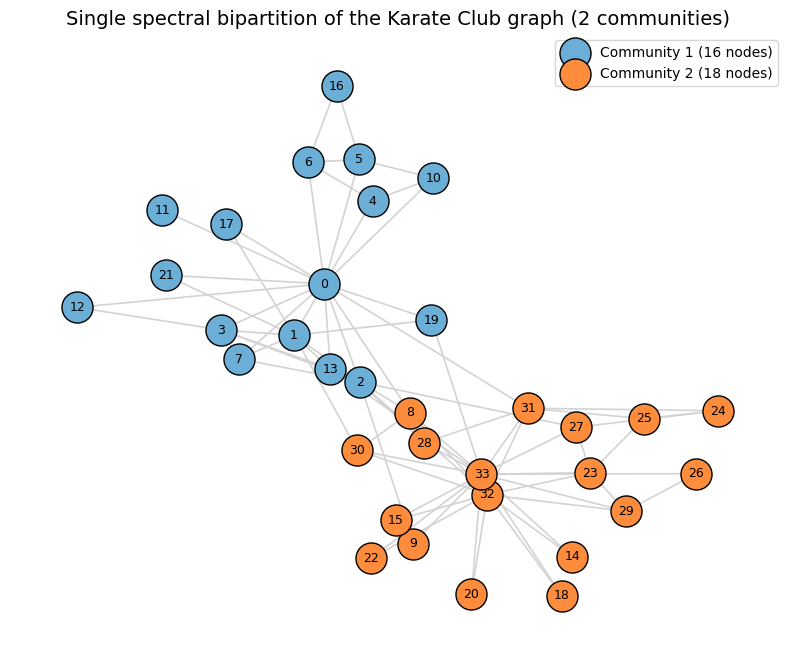

In [ ]:
# Visualise the two communities. This small helper function is reused in Section 8.
def draw_partition(G, pos, partition, title):
    # partition = list of communities, each community is a list of node IDs
    plt.figure(figsize=(10, 8))

    # 1) draw all edges in a neutral grey
    nx.draw_networkx_edges(G, pos, edge_color="lightgray", width=1.2)

    # 2) draw the nodes of each community in its own colour (label = legend entry)
    for index, community in enumerate(partition):
        colour = COLORS[index % len(COLORS)]
        nx.draw_networkx_nodes(G, pos,
                               nodelist=community,
                               node_color=colour,
                               node_size=500,
                               edgecolors="black",
                               label="Community " + str(index + 1) + " (" + str(len(community)) + " nodes)")

    # 3) write the ORIGINAL node ID on every node
    nx.draw_networkx_labels(G, pos, font_size=9, font_color="black")

    plt.title(title, fontsize=14)
    plt.legend(loc="best", scatterpoints=1)
    plt.axis("off")
    plt.show()

draw_partition(G, pos, [group_plus, group_minus],
               "Single spectral bipartition of the Karate Club graph (2 communities)")

**Reading the output.** The signs of the leading eigenvector divide the 34 nodes into two groups with a clearly positive $Q$. We will compare this with the historical factions in Section 12 (not now, so that the algorithm stays independent of the labels).
`s @ B @ s` is below $\lambda_1 n$ as the Rayleigh–Ritz bound says it must be: rounding to $\pm1$ cannot beat the relaxed optimum.

**Drawing functions used:** `nx.draw_networkx_edges` draws the edges, `nx.draw_networkx_nodes(..., nodelist=...)` draws only the listed nodes in one colour, `nx.draw_networkx_labels` writes the IDs, `plt.legend()` shows the `label=` texts, and `pos` keeps the positions fixed.

# Section 7: Recursive spectral partitioning

### Why one split is not enough
Real networks can contain more than two communities. After one bisection each half may still hide internal structure. **Recursion** means a function that solves a problem by calling *itself* on smaller pieces of the same problem. Here: "try to split a community; if it splits, apply the very same procedure to each part."

### The restricted modularity matrix
For a candidate community $C\subseteq V$ the assignment defines
$$
B^{(C)}=B[C,C],\qquad B^{(C)}_{ij}=A_{ij}-\frac{k_ik_j}{2m}\quad (i,j\in C),
$$
that is, **we cut out of the global $B$ the rows and columns belonging to the nodes of $C$.** The degrees $k_i$ and $m$ are always those of the *whole* graph. As instructed in the assignment, we use this definition exactly, with **no diagonal correction**.

In NumPy: `B[np.ix_(rows, cols)]`. **`np.ix_(rows, cols)`** builds the "grid" of all (row, column) pairs, so the result is the $|C|\times|C|$ block. (Plain `B[rows, cols]` would pick only matching *pairs*, a vector, not a block.)

### Algorithm
1. Start with $C=V$ (all nodes).
2. Build $B^{(C)}$ and compute its eigenvalues/eigenvectors with `np.linalg.eigh`.
3. Find the largest eigenvalue $\lambda_1^{(C)}$ and its eigenvector $u_1^{(C)}$.
4. If $\lambda_1^{(C)}>0$ (more precisely $>$ a tiny tolerance): split $C$ into $C^+$ ($u_i>0$) and $C^-$ (otherwise).
5. If $\lambda_1^{(C)}\le0$: stop; $C$ is a final community.
6. Repeat on $C^+$ and $C^-$ separately.

### Why stop when $\lambda_1^{(C)}\le0$?
By Rayleigh–Ritz, $x^TB^{(C)}x\le\lambda_1^{(C)}\|x\|^2$. For a $\pm1$ vector, $\|s\|^2=|C|$, so $s^TB^{(C)}s\le\lambda_1^{(C)}|C|$. If $\lambda_1^{(C)}\le0$, then $s^TB^{(C)}s\le0$ for **every** split, so by the assignment's Theorem 3 ($\Delta Q=\frac1{4m}s^TB^{(C)}s$) no split can help. Different communities can have different $\lambda_1^{(C)}$, so each branch of the recursion stops at its own moment.

### Eigenvalue test versus real modularity gain
The eigenvalue $\lambda_1^{(C)}$ is the maximum of the **relaxed** problem; the algorithm actually applies the **rounded** (sign) vector. So:
* $\lambda_1^{(C)}\le0$ is a safe reason to stop (it rules out *every* $\pm1$ split under the quadratic form $s^TB^{(C)}s$).
* $\lambda_1^{(C)}>0$ only says that a *relaxed* split exists that scores positively. **It does not mathematically guarantee that the sign-thresholded split improves modularity.**
* To be honest about this, after every accepted split we also compute the **actual modularity of the whole partition** before and after, directly from the partition (using only $B$: $Q=\frac1{2m}\sum_{C}\sum_{i,j\in C}B_{ij}$). We call the difference the *actual gain*. This number is a **check**; it is not used to decide splits (the assignment's rule is the eigenvalue rule).
* Remark: Newman's original paper [1] uses a slightly different matrix for sub-communities (it subtracts a diagonal term). The assignment explicitly asks for the plain $B[C,C]$, so that is what we implement.

### Edge cases handled
* A community with fewer than 2 nodes cannot be split (we stop immediately).
* If the sign rule puts *all* nodes on one side (an empty group), the split is rejected.
* Floating-point errors: an eigenvalue like $10^{-15}$ is really 0, so we use the tolerance `TOLERANCE = 1e-8` and require $\lambda_1>$ `TOLERANCE`.

### A note on `global`
Inside the function we *replace* the list `current_partition`. In Python, a function that assigns to a variable defined outside it must declare `global current_partition`, otherwise Python would create a new local variable with the same name.

### What we record
For every *test* we store the step number, iteration number (only for accepted splits), parent community, its nodes, leading eigenvalue, accepted or not, and the children. We also store the **entire partition** after every accepted split, in `partition_history` (entry 0 = everyone in one community).

In [ ]:
TOLERANCE = 1e-8   # eigenvalues <= TOLERANCE are treated as "not positive"


def restricted_modularity_matrix(B, community):
    # B^(C) = B[C, C]: keep only the rows and columns of the nodes in 'community'
    index_list = list(community)
    return B[np.ix_(index_list, index_list)]


def try_to_split(B, community):
    # Returns (leading_eigenvalue, group_plus, group_minus) for one community.
    # Communities with fewer than 2 nodes cannot be split.
    if len(community) < 2:
        return np.nan, [], []

    B_C = restricted_modularity_matrix(B, community)           # |C| x |C| block
    values, vectors = np.linalg.eigh(B_C)                       # eigen-decomposition
    position = np.argmax(values)                                # where the largest is
    leading_value = values[position]
    leading_vector = vectors[:, position]

    # Sign rule: u_i > 0 -> group "+", otherwise group "-"
    group_plus = []
    group_minus = []
    for position_in_C, node in enumerate(community):
        if leading_vector[position_in_C] > 0:
            group_plus.append(node)
        else:
            group_minus.append(node)

    return leading_value, group_plus, group_minus


def partition_modularity(B, partition, m):
    # Q = (1/2m) * sum over communities of (sum of all entries of B[C, C])   -- check only
    total = 0.0
    for community in partition:
        block = restricted_modularity_matrix(B, community)
        total = total + block.sum()
    return total / (2 * m)

In [ ]:
# ----- Storage shared by the recursive function -----
state = {"step": 0, "iteration": 0}          # counters
current_partition = [list(nodes)]            # start: one community with all nodes
partition_history = [[list(nodes)]]          # partition_history[0] = initial partition
log = []                                     # one dictionary per test
modularity_history = [partition_modularity(B, current_partition, m)]   # Q after each iteration


def recursive_split(community):
    # Test one community; if it splits, call this same function on both children.
    global current_partition

    state["step"] = state["step"] + 1
    leading_value, group_plus, group_minus = try_to_split(B, community)

    # Accept only if: eigenvalue clearly positive AND both groups non-empty
    accepted = False
    if len(community) >= 2:
        if leading_value > TOLERANCE:
            if len(group_plus) > 0 and len(group_minus) > 0:
                accepted = True

    if accepted:
        state["iteration"] = state["iteration"] + 1
        iteration_number = state["iteration"]

        # Replace the parent by its two children in the current partition
        new_partition = []
        for existing in current_partition:
            if existing == community:
                new_partition.append(group_plus)
                new_partition.append(group_minus)
            else:
                new_partition.append(existing)
        current_partition = new_partition

        partition_history.append([list(c) for c in current_partition])
        modularity_history.append(partition_modularity(B, current_partition, m))
    else:
        iteration_number = None

    # Why was the community NOT split? (kept for the report)
    if accepted:
        reason = "split accepted"
    elif len(community) < 2:
        reason = "single node (cannot split)"
    elif leading_value <= TOLERANCE:
        reason = "leading eigenvalue <= 0 (stopping criterion)"
    else:
        reason = "eigenvalue > 0 but sign rule gives an empty group (rejected)"

    log.append({"step": state["step"],
                "iteration": iteration_number,
                "parent_size": len(community),
                "parent_nodes": list(community),
                "leading_eigenvalue": leading_value,
                "split_accepted": accepted,
                "reason": reason,
                "child_1": group_plus if accepted else [],
                "child_2": group_minus if accepted else []})

    # Recursion: apply the same procedure to each child
    if accepted:
        recursive_split(group_plus)
        recursive_split(group_minus)


# ----- Run the algorithm on the whole graph -----
recursive_split(list(nodes))

print("Number of tests performed   :", state["step"])
print("Number of accepted splits   :", state["iteration"])
print("Final number of communities :", len(current_partition))

Number of tests performed   : 9
Number of accepted splits   : 4
Final number of communities : 5


In [ ]:
# Table of everything the algorithm did (one row per test)
log_table = pd.DataFrame(log)
display_table = log_table.drop(columns=["child_1", "child_2"]).copy()   # children are shown in the next cell
display_table["leading_eigenvalue"] = display_table["leading_eigenvalue"].round(4)
display_table["iteration"] = display_table["iteration"].astype("Int64")   # show 1,2,3 instead of 1.0,2.0
display_table

,step,iteration,parent_size,parent_nodes,leading_eigenvalue,split_accepted,reason
0,1,1,34,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",4.9771,True,split accepted
1,2,2,16,"[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 1...",2.9441,True,split accepted
2,3,<NA>,10,"[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]",2.5712,False,eigenvalue > 0 but sign rule gives an empty gr...
3,4,3,6,"[4, 5, 6, 10, 11, 16]",2.1480,True,split accepted
4,5,<NA>,1,[11],NaN,False,single node (cannot split)
5,6,<NA>,5,"[4, 5, 6, 10, 16]",2.1470,False,eigenvalue > 0 but sign rule gives an empty gr...
6,7,4,18,"[8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27,...",2.5041,True,split accepted
7,8,<NA>,5,"[24, 25, 27, 28, 31]",1.8759,False,eigenvalue > 0 but sign rule gives an empty gr...
8,9,<NA>,13,"[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32,...",2.3563,False,eigenvalue > 0 but sign rule gives an empty gr...


In [ ]:
# The children of every accepted split
children_table = log_table[log_table["split_accepted"]][["iteration", "parent_size", "child_1", "child_2"]].copy()
children_table["iteration"] = children_table["iteration"].astype("Int64")
children_table

,iteration,parent_size,child_1,child_2
0,1,34,"[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 1...","[8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27,..."
1,2,16,"[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]","[4, 5, 6, 10, 11, 16]"
3,3,6,[11],"[4, 5, 6, 10, 16]"
6,4,18,"[24, 25, 27, 28, 31]","[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32,..."


**Reading the table.** Each row is one test of a community. `split_accepted = True` means the eigenvalue was positive and both child groups are non-empty; those rows get an iteration number. The `reason` column says why every other community was kept whole. Different branches stop at different steps, as explained above.

**Important observation (read the `reason` column).** A community can be rejected for two different reasons: (a) its leading eigenvalue is $\le0$ (the assignment's stopping criterion), or (b) its leading eigenvalue is positive, but **all entries of the leading eigenvector have the same sign**, so the sign rule would put every node on one side and the other group would be empty. Case (b) is exactly the "splits that produce an empty group" edge case. It can happen because the restricted block $B[C,C]$ (used exactly as the assignment defines it, without a diagonal correction) no longer has zero row sums, so its leading eigenvector does not have to contain both positive and negative entries. In case (b) no split is possible with this sign rule, so the community is kept. The next cell shows the actual modularity after each iteration, and then verifies the partitions.

In [ ]:
# Modularity of the whole partition after each accepted split (CHECK of the eigenvalue rule)
rows = []
for iteration, partition in enumerate(partition_history):
    q_value = modularity_history[iteration]
    nx_q = nx.community.modularity(G, [set(c) for c in partition], weight=None)
    if iteration == 0:
        gain = 0.0
    else:
        gain = q_value - modularity_history[iteration - 1]
    rows.append({"iteration": iteration,
                 "number_of_communities": len(partition),
                 "Q (from B)": round(q_value, 4),
                 "Q (NetworkX check)": round(nx_q, 4),
                 "actual gain in Q": round(gain, 4)})
Q_table = pd.DataFrame(rows)
print(Q_table.to_string(index=False))

# ---------- Verification: every node in exactly one community at every iteration ----------
for iteration, partition in enumerate(partition_history):
    all_nodes_listed = []
    for community in partition:
        for node in community:
            all_nodes_listed.append(node)
    assert len(all_nodes_listed) == n, "A node was lost or duplicated"
    assert sorted(all_nodes_listed) == nodes, "Node set changed"
    assert all(len(c) > 0 for c in partition), "Empty community found"
print("\nCheck passed: at every iteration each of the", n, "nodes is in exactly one community.")

# Check the eigenvalue stopping rule on the final communities
print("\nLeading eigenvalue of every FINAL community and why it was not split further:")
for community in current_partition:
    value, plus, minus = try_to_split(B, community)
    print("  size", len(community), "-> lambda_1 =", None if np.isnan(value) else round(value, 4),
          "| group sizes by sign:", (len(plus), len(minus)), "| nodes:", community)

 iteration  number_of_communities  Q (from B)  Q (NetworkX check)  actual gain in Q
         0                      1     -0.0000              0.0000            0.0000
         1                      2      0.3715              0.3715            0.3715
         2                      3      0.3898              0.3898            0.0183
         3                      4      0.3911              0.3911            0.0013
         4                      5      0.4094              0.4094            0.0183

Check passed: at every iteration each of the 34 nodes is in exactly one community.

Leading eigenvalue of every FINAL community and why it was not split further:
  size 10 -> lambda_1 = 2.5712 | group sizes by sign: (10, 0) | nodes: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  size 1 -> lambda_1 = None | group sizes by sign: (0, 0) | nodes: [11]
  size 5 -> lambda_1 = 2.147 | group sizes by sign: (5, 0) | nodes: [4, 5, 6, 10, 16]
  size 5 -> lambda_1 = 1.8759 | group sizes by sign: (0, 5) | nodes:

**Reading the output.** The table lists the modularity after every accepted split. `Q (from B)` is computed from our matrix $B$ and agrees with `Q (NetworkX check)`, which confirms our matrix and formulas are implemented correctly. The last column is the *actual* modularity gain of the sign-thresholded split. The verification confirms that no node is lost or duplicated at any iteration, and that every final community is indeed one the eigenvalue rule refuses to split further.

# Section 8: Visualising the recursive splitting process

For **every** stage (iteration 0 = the whole graph, then after each accepted split) we draw the *complete original graph* with:
* the same positions `pos` in every figure (so you can compare pictures),
* a different colour for each community (`draw_partition` from Section 6),
* every node labelled with its original ID,
* neutral grey edges, a legend, and the iteration number in the title.

The loop below uses `enumerate(partition_history)`, which gives the iteration number together with the partition stored at that iteration.

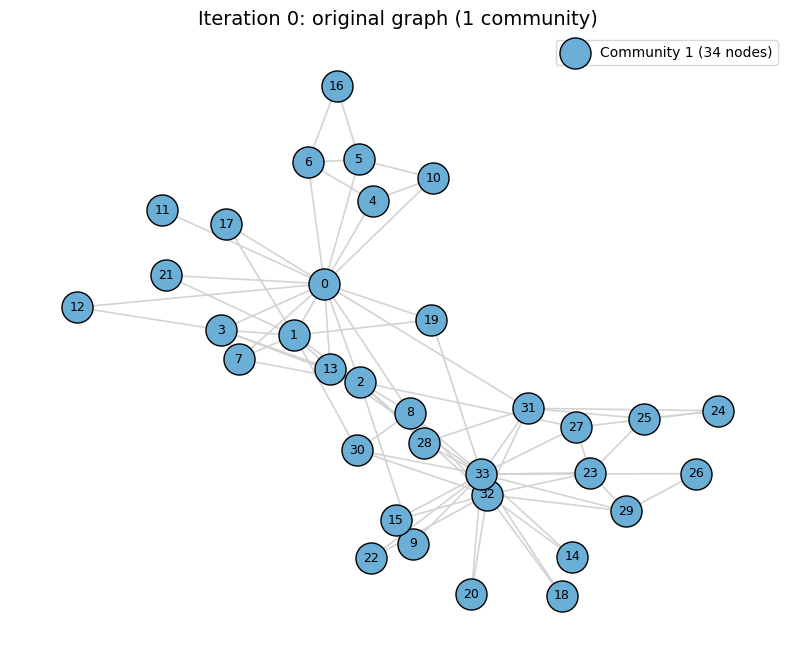

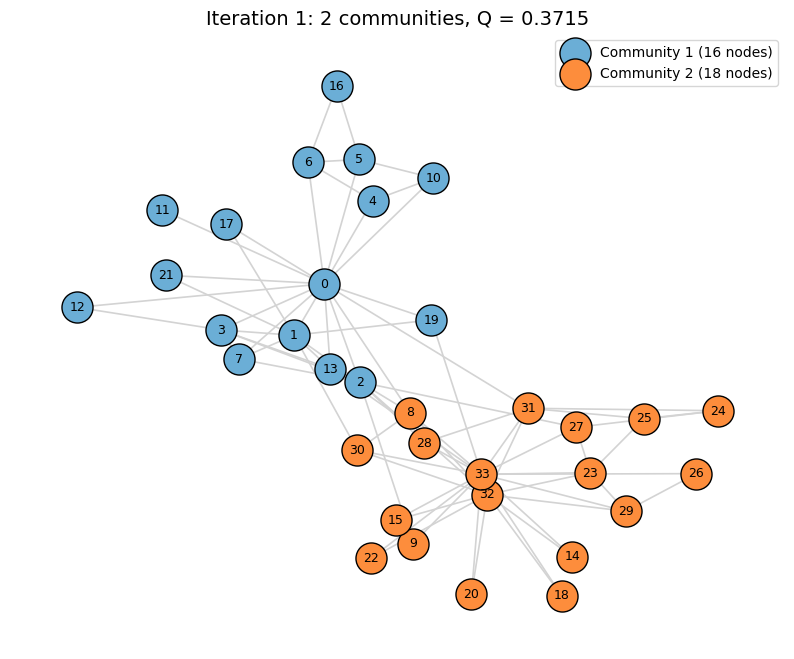

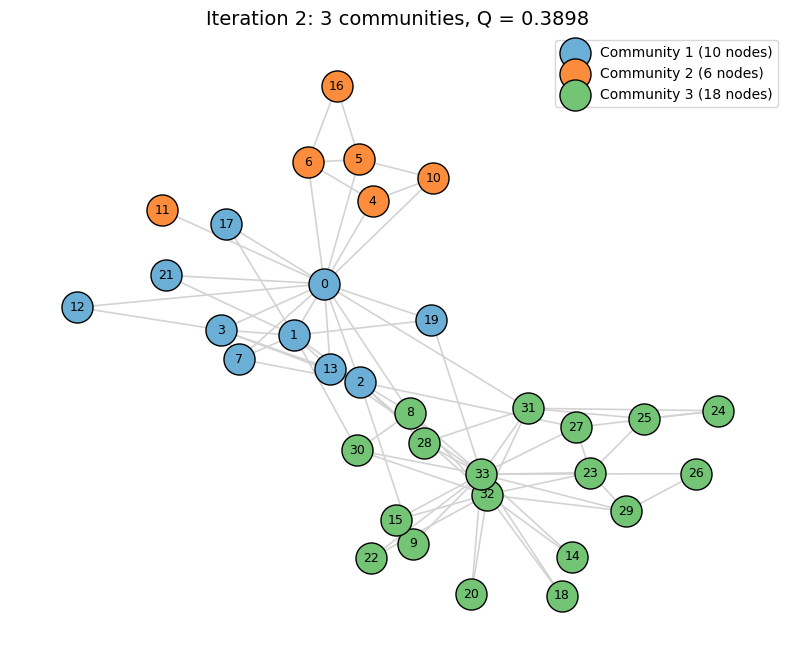

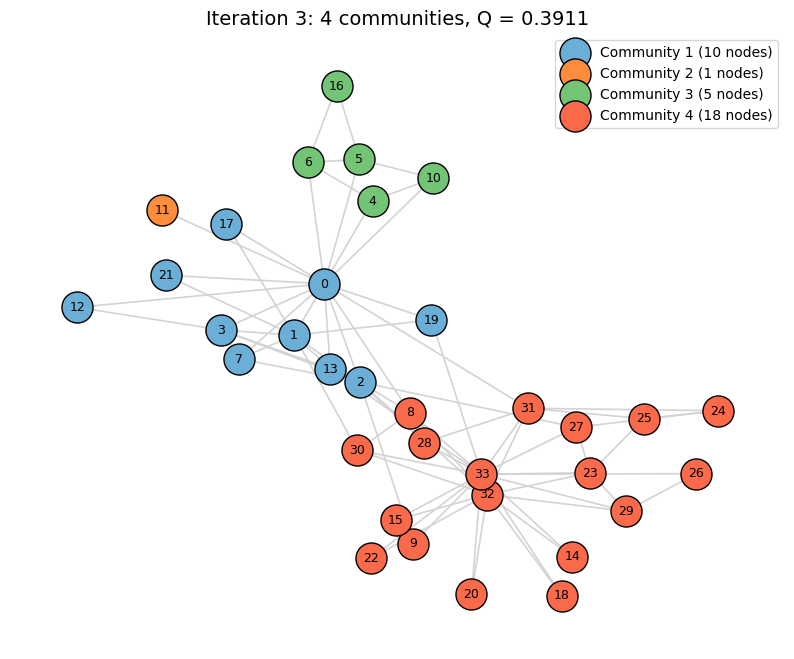

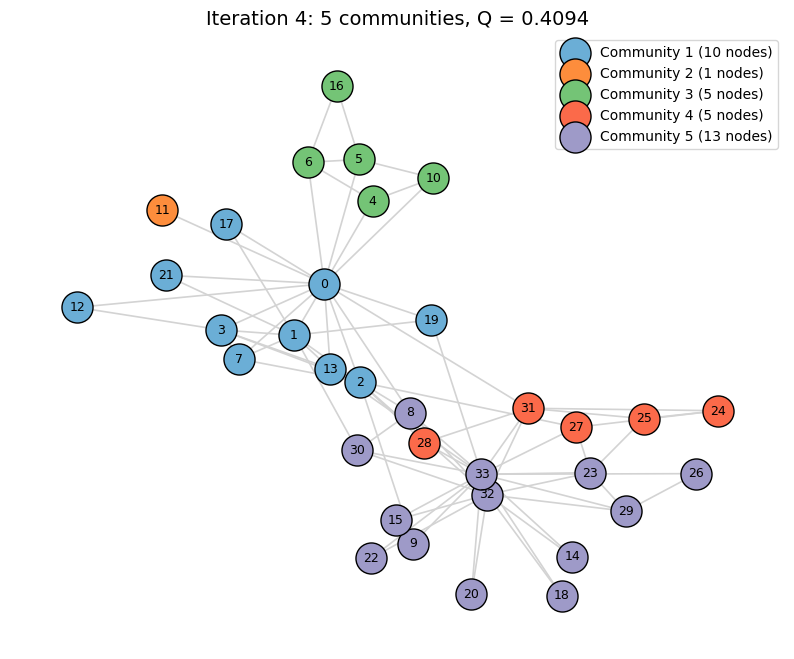

In [ ]:
for iteration, partition in enumerate(partition_history):
    if iteration == 0:
        title = "Iteration 0: original graph (1 community)"
    else:
        title = ("Iteration " + str(iteration) + ": " + str(len(partition)) +
                 " communities, Q = " + str(round(modularity_history[iteration], 4)))
    draw_partition(G, pos, partition, title)

**Reading the figures.** The picture shows how the club is progressively divided: first into two big groups, then those groups are cut into smaller communities one branch at a time. Node positions never change; only colours do. Edges between differently coloured nodes are the edges that are "cut" by the partition.

# Section 9: Calculating network metrics

After every accepted split we compute four metrics for every node. They are computed on the **induced subgraph of the community the node currently belongs to**: `G.subgraph(community)` keeps only the nodes of that community and the edges *between* them. So they are **within-community metrics**. The original graph `G` itself is never modified (a subgraph is only a view).

Convention used:
* **Iteration 0:** metrics on the whole graph (one community = all nodes).
* **After each accepted split:** metrics on each current community's induced subgraph.
* **Final iteration:** metrics on the final communities (the last stage).

> Special case: a community with a single node has no neighbours, so we set all four metrics to 0 for it (centralities divide by $n-1=0$).
> Note: a community might be internally disconnected; NetworkX handles closeness for such graphs, see below.

### A. Degree centrality — `nx.degree_centrality(subgraph)`
$$C_D(i)=\frac{k_i}{n-1}$$
where $k_i$ is the number of neighbours of $i$ *inside the subgraph* and $n$ is the number of nodes in the subgraph. It is the fraction of the other nodes that $i$ is directly linked to. **High value = hub** with many direct contacts. *Returns:* a dictionary `{node: value}`.

### B. Betweenness centrality — `nx.betweenness_centrality(subgraph)`
$$C_B(i)=\sum_{s\ne i\ne t}\frac{\sigma_{st}(i)}{\sigma_{st}}$$
where $\sigma_{st}$ is the number of shortest paths between $s$ and $t$ and $\sigma_{st}(i)$ is how many of them pass through $i$. (NetworkX additionally **normalises** by the number of node pairs, so values lie between 0 and 1.) **High value = bridge/broker**: removing it would lengthen or break many shortest routes between other nodes.

### C. Closeness centrality — `nx.closeness_centrality(subgraph)`
$$C_C(i)=\frac{n-1}{\sum_{j\ne i}d(i,j)}$$
where $d(i,j)$ is the shortest-path distance (number of edges). It is the inverse of the *average distance* from $i$ to the others. **High value = easily reachable / can reach everybody quickly.** (For disconnected subgraphs NetworkX scales the value by the fraction of reachable nodes, so it still works.)

### D. Clustering coefficient — `nx.clustering(subgraph)`
$$C(i)=\frac{2T(i)}{k_i(k_i-1)}$$
where $T(i)$ is the number of **triangles** through $i$ (three mutually connected nodes: $i$ and two of its neighbours that are also connected). It is the fraction of pairs of neighbours of $i$ that are themselves connected. **High value = tight local neighbourhood** (friends of $i$ know each other); nodes with $k_i<2$ get 0.

All four functions take a graph and return a dictionary mapping each node to its value; the function below calls them for every community and collects the results into rows.

In [ ]:
def metrics_for_partition(G, partition, iteration):
    # Returns a list of rows (dictionaries): one row per node, for one iteration.
    rows = []

    for community_number, community in enumerate(partition, start=1):
        subgraph = G.subgraph(community)          # only this community's nodes and internal edges

        if len(community) == 1:
            # a single node: nothing to compare with
            degree_c = {community[0]: 0.0}
            between_c = {community[0]: 0.0}
            close_c = {community[0]: 0.0}
            cluster_c = {community[0]: 0.0}
        else:
            degree_c = nx.degree_centrality(subgraph)
            between_c = nx.betweenness_centrality(subgraph)
            close_c = nx.closeness_centrality(subgraph)
            cluster_c = nx.clustering(subgraph)

        for node in community:
            rows.append({"iteration": iteration,
                         "community_id": community_number,
                         "node": node,
                         "degree_centrality": degree_c[node],
                         "betweenness_centrality": between_c[node],
                         "closeness_centrality": close_c[node],
                         "clustering_coefficient": cluster_c[node]})
    return rows


# quick test on iteration 0 (whole graph): look at nodes 0, 33, 11
test_rows = metrics_for_partition(G, partition_history[0], 0)
test_table = pd.DataFrame(test_rows)
test_table[test_table["node"].isin([0, 33, 11])].round(4)

,iteration,community_id,node,degree_centrality,betweenness_centrality,closeness_centrality,clustering_coefficient
0,0,1,0,0.4848,0.4376,0.5690,0.1500
11,0,1,11,0.0303,0.0000,0.3667,0.0000
33,0,1,33,0.5152,0.3041,0.5500,0.1103


**Reading the output.** For the whole graph node 0 and node 33 have the largest degree and betweenness, while node 11 (degree 1, attached only to node 0) has clustering 0 and tiny betweenness. This is the expected picture for the Karate Club.

# Section 10: Storing the metric values

We loop over `partition_history` (iteration 0, 1, 2, …) and call `metrics_for_partition` each time. All rows are put into **one tidy Pandas DataFrame** called `metric_history` with the columns:

`iteration | community_id | node | degree_centrality | betweenness_centrality | closeness_centrality | clustering_coefficient`

This "one row = one node at one iteration" layout (a *long* table) is easy to filter and, with `pivot`, easy to turn into one line per node for plotting. All values come from NetworkX computations on the real graphs.

In [ ]:
all_rows = []
for iteration, partition in enumerate(partition_history):
    rows_for_iteration = metrics_for_partition(G, partition, iteration)
    for row in rows_for_iteration:
        all_rows.append(row)

metric_history = pd.DataFrame(all_rows)

print("Table shape:", metric_history.shape,
      "= (iterations x nodes) rows =", len(partition_history), "x", n, "=", len(partition_history) * n)
print("Every iteration has all nodes? ",
      all(metric_history.groupby("iteration")["node"].nunique() == n))

metric_history.round(4)

Table shape: (170, 7) = (iterations x nodes) rows = 5 x 34 = 170
Every iteration has all nodes?  True


,iteration,community_id,node,degree_centrality,betweenness_centrality,closeness_centrality,clustering_coefficient
0,0,1,0,0.4848,0.4376,0.5690,0.1500
1,0,1,1,0.2727,0.0539,0.4853,0.3333
2,0,1,2,0.3030,0.1437,0.5593,0.2444
3,0,1,3,0.1818,0.0119,0.4648,0.6667
4,0,1,4,0.0909,0.0006,0.3793,0.6667
5,0,1,5,0.1212,0.0300,0.3837,0.5000
6,0,1,6,0.1212,0.0300,0.3837,0.5000
7,0,1,7,0.1212,0.0000,0.4400,1.0000
8,0,1,8,0.1515,0.0559,0.5156,0.5000
9,0,1,9,0.0606,0.0008,0.4342,0.0000


**Reading the output.** The table has one row for each (iteration, node) pair. The `community_id` column tells us which community the node belonged to at that iteration (at iteration 0 everyone is in community 1). The check line confirms that every node is present at every iteration.

### Original full-graph metrics vs final within-community metrics
Below, the left four columns (`_orig`) are iteration 0 and the right four (`_final`) are the final iteration. The `community_id_final` column shows each node's final community.

In [ ]:
final_iteration = len(partition_history) - 1

original = metric_history[metric_history["iteration"] == 0].set_index("node")
final = metric_history[metric_history["iteration"] == final_iteration].set_index("node")

metric_names = ["degree_centrality", "betweenness_centrality",
                "closeness_centrality", "clustering_coefficient"]

comparison = pd.DataFrame(index=original.index)
for name in metric_names:
    comparison[name + "_orig"] = original[name]
for name in metric_names:
    comparison[name + "_final"] = final[name]
comparison["community_id_final"] = final["community_id"]

comparison.round(3)

,degree_centrality_orig,betweenness_centrality_orig,closeness_centrality_orig,clustering_coefficient_orig,degree_centrality_final,betweenness_centrality_final,closeness_centrality_final,clustering_coefficient_final,community_id_final
node,,,,,,,,,
0,0.485,0.438,0.569,0.150,1.000,0.354,1.000,0.361,1
1,0.273,0.054,0.485,0.333,0.889,0.215,0.900,0.429,1
2,0.303,0.144,0.559,0.244,0.556,0.007,0.692,0.900,1
3,0.182,0.012,0.465,0.667,0.667,0.062,0.750,0.667,1
4,0.091,0.001,0.379,0.667,0.500,0.083,0.667,0.000,3
5,0.121,0.030,0.384,0.500,0.750,0.250,0.800,0.333,3
6,0.121,0.030,0.384,0.500,0.750,0.250,0.800,0.333,3
7,0.121,0.000,0.440,1.000,0.444,0.000,0.643,1.000,1
8,0.152,0.056,0.516,0.500,0.250,0.000,0.571,1.000,5


**Reading the output.** Final values are generally different from the original values because they are measured *inside* small communities. For example, degree and closeness are divided by the (small) community size minus 1, and shortest paths are only searched inside the community. These are **not** directly comparable with full-graph values; they show how important a node is *within its own community*.

# Section 11: Plotting metric evolution

We make four plots (one per metric). In each plot:
* **x-axis:** iteration number, **y-axis:** metric value,
* **each line is one node** (original ID),
* the legend is placed **outside** the plot in two columns, so that 34 entries do not cover the lines.

`table = metric_history.pivot(index="iteration", columns="node", values=metric)` reshapes the long table into a wide table: one row per iteration and one column per node. Then `ax.plot(x, y)` draws one line per column.

To make the plots easier to read, the **five nodes with the highest value at iteration 0** are drawn with thicker lines, and all other nodes with thin, light lines.

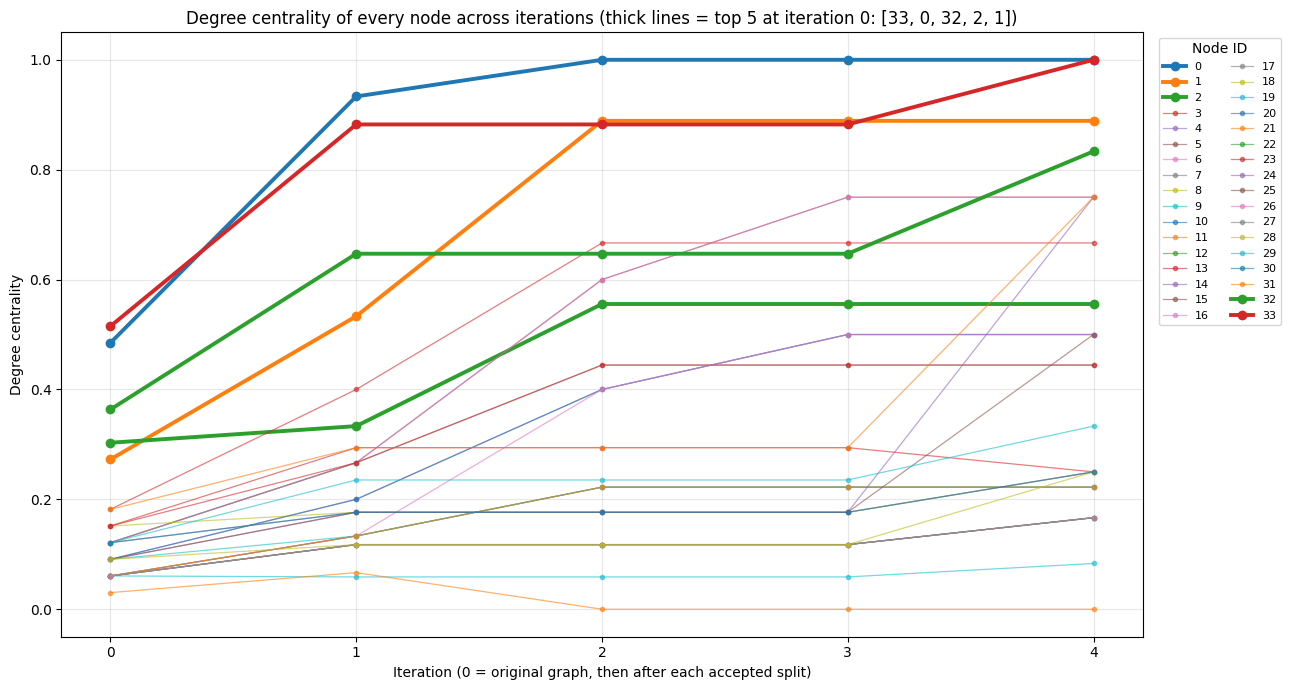

In [ ]:
def plot_metric_evolution(metric_column, nice_name):
    # one row per iteration, one column per node
    table = metric_history.pivot(index="iteration", columns="node", values=metric_column)

    # five nodes with the highest value at iteration 0 (they get thick lines)
    top_five = table.loc[0].sort_values(ascending=False).head(5).index.tolist()

    fig, ax = plt.subplots(figsize=(13, 7))
    for node in table.columns:
        if node in top_five:
            ax.plot(table.index, table[node], marker="o", linewidth=2.8, label=str(node))
        else:
            ax.plot(table.index, table[node], marker=".", linewidth=0.9, alpha=0.6, label=str(node))

    ax.set_xticks(list(table.index))
    ax.set_xlabel("Iteration (0 = original graph, then after each accepted split)")
    ax.set_ylabel(nice_name)
    ax.set_title(nice_name + " of every node across iterations (thick lines = top 5 at iteration 0: "
                 + str(top_five) + ")")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Node ID", loc="upper left", bbox_to_anchor=(1.01, 1.0), ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()


plot_metric_evolution("degree_centrality", "Degree centrality")

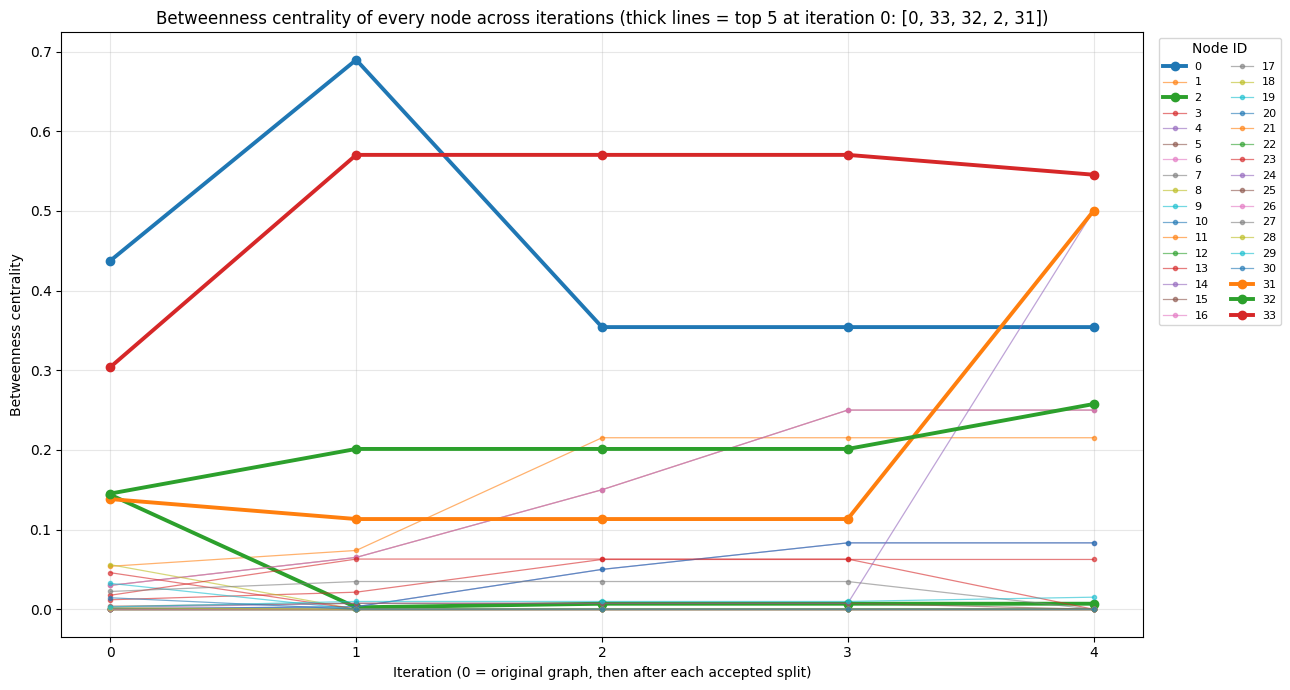

In [ ]:
plot_metric_evolution("betweenness_centrality", "Betweenness centrality")

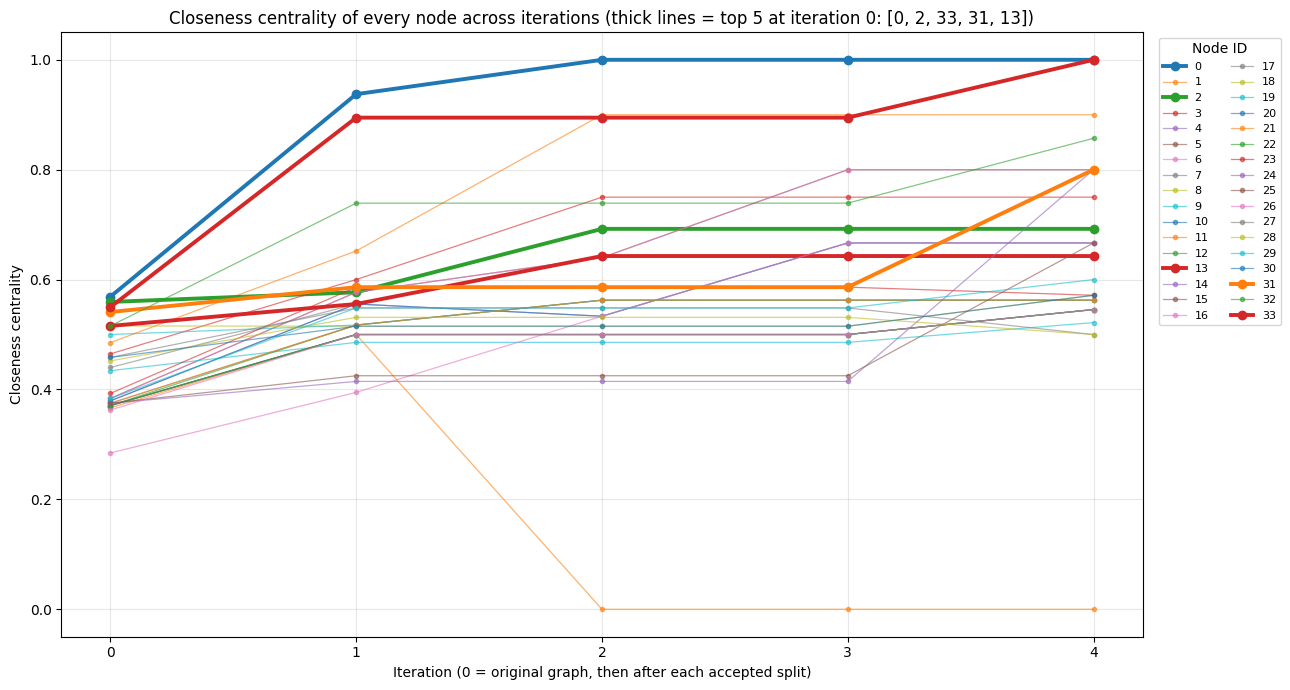

In [ ]:
plot_metric_evolution("closeness_centrality", "Closeness centrality")

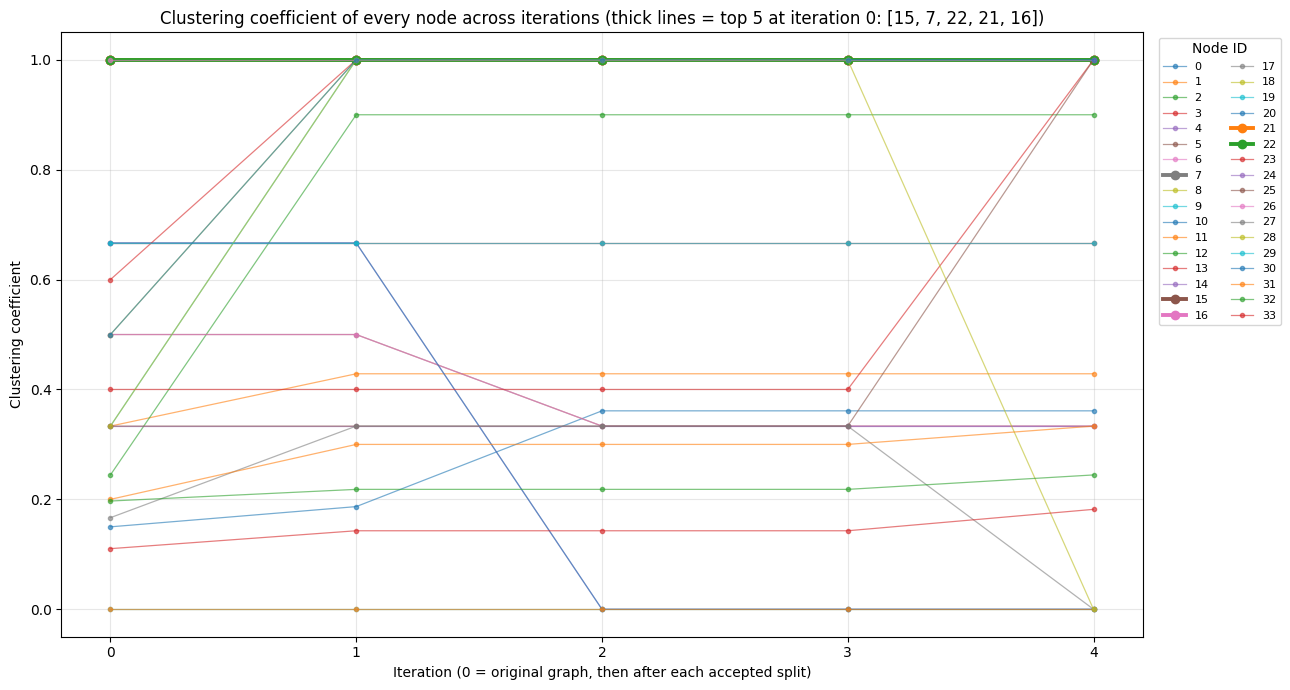

In [ ]:
plot_metric_evolution("clustering_coefficient", "Clustering coefficient")

### How to read these plots
* **Degree centrality:** when a node's community becomes smaller, the denominator $n-1$ shrinks and edges leaving the community are no longer counted, so values change. A node whose neighbours mostly lie inside its community keeps a high value.
* **Betweenness centrality:** at iteration 0 it is high for nodes that connect different parts of the whole graph. After splitting, paths between different communities are no longer counted, so the "bridge" role between communities disappears from the within-community value; a new, local broker role appears inside each community.
* **Closeness centrality:** smaller communities have shorter distances, so many nodes get higher closeness inside their own community.
* **Clustering coefficient:** removing the edges that cross communities can only delete triangles that used cross edges, so a node's clustering usually stays the same or changes slightly, and increases when low-clustering cross-community neighbours are removed.

The detailed statements about *which* nodes do what are given in Section 13 using the actual numbers.

# Section 12: Comparing detected communities with the historical factions

Only now do we use the historical labels stored in `G.nodes[node]["club"]` (`'Mr. Hi'` or `'Officer'`). They were **never** used in $B$, in the eigenvectors, or in the splitting; they are used only to *evaluate* the result afterwards. We do not tune or force anything to match them.

In [ ]:
rows = []
for community_number, community in enumerate(current_partition, start=1):
    count_mr_hi = 0
    count_officer = 0
    for node in community:
        if G.nodes[node]["club"] == "Mr. Hi":
            count_mr_hi = count_mr_hi + 1
        else:
            count_officer = count_officer + 1
    rows.append({"detected_community": community_number,
                 "size": len(community),
                 "Mr. Hi": count_mr_hi,
                 "Officer": count_officer,
                 "nodes": sorted(community)})
faction_table = pd.DataFrame(rows)
faction_table

,detected_community,size,Mr. Hi,Officer,nodes
0,1,10,10,0,"[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]"
1,2,1,1,0,[11]
2,3,5,5,0,"[4, 5, 6, 10, 16]"
3,4,5,0,5,"[24, 25, 27, 28, 31]"
4,5,13,1,12,"[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32,..."


In [ ]:
# Also check the very FIRST split (iteration 1) against the two historical factions
first_plus = log[0]["child_1"]
first_minus = log[0]["child_2"]
print("First split, group +1:", sorted(first_plus))
print("   historical factions:", pd.Series([G.nodes[x]["club"] for x in first_plus]).value_counts().to_dict())
print("First split, group -1:", sorted(first_minus))
print("   historical factions:", pd.Series([G.nodes[x]["club"] for x in first_minus]).value_counts().to_dict())

# Total number of nodes that would be 'misclassified' by the first split
# (we do not know which group is which, so we take the smaller of the two possible mismatch counts)
mr_hi_nodes = [x for x in nodes if G.nodes[x]["club"] == "Mr. Hi"]
mismatch_a = len(set(first_plus) ^ set(mr_hi_nodes))              # group + = Mr. Hi
mismatch_b = n - mismatch_a                                       # group + = Officer
print("\nNodes in a different group than the historical faction (first split):",
      min(mismatch_a, mismatch_b))

First split, group +1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
   historical factions: {'Mr. Hi': 16}
First split, group -1: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
   historical factions: {'Officer': 17, 'Mr. Hi': 1}

Nodes in a different group than the historical faction (first split): 1


# Section 13: Results and discussion

The cell below extracts the facts that the discussion refers to **directly from the stored results** (nothing typed by hand). The discussion text follows after the output.

In [ ]:
final_iteration = len(partition_history) - 1
full = metric_history[metric_history["iteration"] == 0].set_index("node")
last = metric_history[metric_history["iteration"] == final_iteration].set_index("node")

print("Number of detected communities:", len(current_partition))
print("Community sizes               :", [len(c) for c in current_partition])
print("Final modularity Q            :", round(modularity_history[-1], 4))

for name in metric_names:
    print("\n=== " + name + " ===")
    print("Top 5 on the FULL graph (iteration 0):")
    print(full[name].sort_values(ascending=False).head(5).round(3).to_dict())
    print("Top 5 within communities (final iteration):")
    print(last[name].sort_values(ascending=False).head(5).round(3).to_dict())

print("\nMean clustering coefficient and mean metrics per final community:")
summary = last.groupby("community_id")[metric_names].mean().round(3)
summary["size"] = last.groupby("community_id").size()
summary["nodes"] = [sorted(c) for c in current_partition]
print(summary.to_string())

print("\nMean of each metric over all nodes, by iteration:")
print(metric_history.groupby("iteration")[metric_names].mean().round(3).to_string())

# Nodes that are in the top 5 for betweenness in the full graph AND final within-community
top_b_full = set(full["betweenness_centrality"].sort_values(ascending=False).head(5).index)
top_b_last = set(last["betweenness_centrality"].sort_values(ascending=False).head(5).index)
print("\nTop-5 betweenness in both full graph and final stage:", sorted(top_b_full & top_b_last))

# How often is each node in the top 5 of degree centrality across ALL iterations?
for name in ["degree_centrality", "betweenness_centrality", "closeness_centrality"]:
    counts = {}
    for iteration in range(len(partition_history)):
        part = metric_history[metric_history["iteration"] == iteration].set_index("node")
        for node in part[name].sort_values(ascending=False).head(5).index:
            counts[node] = counts.get(node, 0) + 1
    ordered = sorted(counts.items(), key=lambda pair: -pair[1])
    print("Times in top-5 for", name, "(out of", len(partition_history), "iterations):", ordered[:6])

Number of detected communities: 5
Community sizes               : [10, 1, 5, 5, 13]
Final modularity Q            : 0.4094

=== degree_centrality ===
Top 5 on the FULL graph (iteration 0):
{33: 0.515, 0: 0.485, 32: 0.364, 2: 0.303, 1: 0.273}
Top 5 within communities (final iteration):
{0: 1.0, 33: 1.0, 1: 0.889, 32: 0.833, 5: 0.75}

=== betweenness_centrality ===
Top 5 on the FULL graph (iteration 0):
{0: 0.438, 33: 0.304, 32: 0.145, 2: 0.144, 31: 0.138}
Top 5 within communities (final iteration):
{33: 0.545, 24: 0.5, 31: 0.5, 0: 0.354, 32: 0.258}

=== closeness_centrality ===
Top 5 on the FULL graph (iteration 0):
{0: 0.569, 2: 0.559, 33: 0.55, 31: 0.541, 13: 0.516}
Top 5 within communities (final iteration):
{0: 1.0, 33: 1.0, 1: 0.9, 32: 0.857, 5: 0.8}

=== clustering_coefficient ===
Top 5 on the FULL graph (iteration 0):
{15: 1.0, 7: 1.0, 22: 1.0, 21: 1.0, 16: 1.0}
Top 5 within communities (final iteration):
{7: 1.0, 12: 1.0, 30: 1.0, 22: 1.0, 17: 1.0}

Mean clustering coefficient a

## Discussion (based on the outputs above)

**1. Number of communities.** The recursive algorithm accepted **4 splits** and ended with **5 communities** of sizes 10, 1, 5, 5 and 13. The modularity of the partition rose from 0 (everyone together) to 0.3715 (iteration 1), 0.3898, 0.3911 and finally **0.4094** (iteration 4). In this run every accepted split had a positive *actual* gain in $Q$ (0.3715, 0.0183, 0.0013, 0.0183), but this is an observation, not something the eigenvalue test guarantees (Section 7).

**Why the recursion stopped.** Four communities (sizes 10, 5, 5, 13) still have a *positive* leading eigenvalue (about 2.57, 2.15, 1.88 and 2.36), yet were not split, because the sign rule put all their nodes on the same side (an empty group), so no split exists with this rule. The single node [11] cannot be split. So in this run the recursion ended through the empty-group rule, not through "$\lambda_1\le0$". The restricted block $B[C,C]$ is used exactly as the assignment defines it (no diagonal correction), which is why its leading eigenvector can be one-signed. Also, node 11 (degree 1, linked only to node 0) was split off as a singleton at iteration 3; the actual modularity gain of that step was very small (0.0013).

**2. Highest degree centrality.** On the full graph: node **33** (0.515), node **0** (0.485), node 32 (0.364), node 2 (0.303), node 1 (0.273). Nodes 0, 33 and 1 are in the top five at **all five** stages, node 32 at four. These are the club's most-connected members (the two leaders are 0 and 33).

**3 & 4. Betweenness and bridges.** On the full graph: node **0** (0.438), node **33** (0.304), then nodes 32 (0.145), 2 (0.144) and 31 (0.138). Nodes 0 and 33 are in the top five for betweenness at all five stages, node 32 at four stages and node 31 at three. These are the main brokers/bridges. Several nodes lose their bridge role after the first split: node 2 falls from 0.144 to 0.002, which is consistent with its shortest paths to the other side of the club no longer being counted. Node 0 rises to 0.690 at iteration 1 (it is the main broker inside its 16-node group) and then falls to 0.354 once that group is divided. After the last split nodes 24 and 31 reach 0.500 because they connect the other members of their small community; this is a *local* role inside a community of five nodes, not a global one.

**5. Closeness.** On the full graph: node **0** (0.569), node 2 (0.559), node **33** (0.550), node 31 (0.541), node 13 (0.516); values are close together (the graph is small and compact). Within the final communities nodes 0 and 33 reach closeness 1.0 (every other node in their community is a direct neighbour), then nodes 1 (0.900), 32 (0.857) and 5 (0.800).

**6. Clustering by community.** Final mean clustering coefficients: community of nodes {0,1,2,3,7,12,13,17,19,21} 0.836, community of 13 nodes {8,…,33} 0.776, communities {4,5,6,10,16} and {24,25,27,28,31} 0.333 each, singleton {11} 0. So the two large communities are the most tightly knit. The hubs themselves have low clustering: node 0 has 0.150 and node 33 has 0.110 on the full graph (their neighbours do not know each other, they link different groups); inside communities they rise to 0.361 and 0.182.

**7. How the metrics change.** Averaged over all nodes, from iteration 0 to the final iteration: degree centrality 0.139 → 0.423, betweenness 0.044 → 0.092, closeness 0.426 → 0.639, clustering 0.571 → 0.641 (clustering rose to 0.684 after the first split and then stayed around 0.64). The increase in degree and closeness is mainly a **size effect**: inside a small community the denominator $n-1$ is small and distances are short. Edges that leave a community are not counted, so these are within-community values and not directly comparable with the full-graph values. Nodes that were bridges between communities lose that role, and nodes with mostly internal edges keep high values.

**Which nodes consistently remain central?** Nodes **0** and **33** are in the top five for degree, betweenness *and* closeness at every one of the five stages; node 1 is in the top five for degree at every stage (and for closeness at four), and node 32 is in the top five for degree and betweenness at four stages. Their importance does not depend on how the club is divided.

**8. Comparison with the historical split.** The first split (16 nodes versus 18 nodes) agrees with the historical factions for 33 of 34 members: the 16-node group is entirely "Mr. Hi", the 18-node group contains 17 "Officer" members and one "Mr. Hi" member (node 8). The final five communities refine this split: communities {0,1,2,3,7,12,13,17,19,21}, {11} and {4,5,6,10,16} contain only "Mr. Hi" members, community {24,25,27,28,31} contains only "Officer" members, and the 13-node community has 12 "Officer" members and node 8. So the detected structure resembles the historical division, and the later splits find sub-groups *inside* the two factions. The historical labels were never used by the algorithm.

*Limitations.* The spectral method is an approximation to modularity maximisation, the result depends on using $B[C,C]$ without a diagonal correction (as the assignment specifies), and the later splits improve modularity only slightly (0.3715 → 0.4094), so the first split is by far the most important one.

# Section 14: Conclusion

**Modularity** measures how much more strongly a group of nodes is connected inside than a random graph with the same degrees would predict. The **modularity matrix** is $B=A-\frac{kk^T}{2m}$: the actual adjacency minus the expected edge counts of the degree-preserving null model. $B$ is real symmetric and each row sums to zero. The modularity of a two-way split $s\in\{\pm1\}^n$ is $Q=\frac1{4m}s^TBs$.

**Spectral partitioning** relaxes $s$ to a unit real vector. By the Rayleigh–Ritz theorem the maximum of $s^TBs$ is the largest eigenvalue $\lambda_1$, attained by the leading eigenvector $u_1$; its signs give the two groups. This is an approximation and not a guarantee of the best discrete split.

**Recursive bisection** applies the same procedure to the restricted matrix $B[C,C]$ of each community. A community with $\lambda_1^{(C)}\le0$ cannot be improved by any split (Theorem 3), so it is left alone; a positive eigenvalue only *allows* a split and does not guarantee a gain, and in our run the sign rule also had to be checked for empty groups. On the Karate Club graph the method produced 5 communities with $Q=0.4094$; the first split reproduces the historical division except for one member (node 8).

**Network metrics.** Nodes 0 and 33 are the most central by degree, betweenness and closeness at every stage, and have low clustering because they connect different groups. Within-community metrics are larger on average than full-graph metrics because the communities are small. The two large communities have the highest clustering (0.836 and 0.776).

# Section 15: References

1. Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences, 103*(23), 8577–8582.
2. Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research, 33*(4), 452–473. (Source of the Karate Club data.)
3. NetworkX documentation: https://networkx.org  &nbsp;|&nbsp; NumPy documentation: https://numpy.org/doc